# Analysis of data about AI usage by students and professionals

* Author: Dora Kovačević
* Date: October 2026

## Loading data set

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("C:/Users/Dora/Downloads/archive/AI_Usage_and_Impact_on_Students_and_Professionals.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    str    
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    str    
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    str    
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    str    
 13  Productivity_Score           28

## Cleaning  

* numeric data currently saved as strings
* case sensitive columns
* different names for the same country
* etc.

### Checking unique data, column by column
After checking, I will try to improve each column for which it's possible

In [3]:
df['Age'].unique()

<ArrowStringArray>
[    '30',     '17',     '35',     '19',     '32',     '16',     '40',
     '36',     '22',     '21',     '28', '16 yrs',     '23',     '61',
     '24',     '29', '23 yrs',      nan,     '44',     '18',     '45',
     '43',     '20',     '34',     '26',     '33',     '31', '21 yrs',
 '47 yrs',     '37',     '39',     '25',     '46', '25 yrs',     '97',
     '54',     '47', '30 yrs', '28 yrs',     '27',     '56',     '63',
     '41',     '58',     '49',     '55', '39 yrs',     '48', '17 yrs',
     '53',     '64',     '38', '36 yrs']
Length: 53, dtype: str

Age could be numeric, just needs a few changes

In [4]:
df['Age'] = df['Age'].str.replace('yrs', '', case=False).str.strip()
df['Age'] = pd.to_numeric(df['Age'])

In [5]:
df['Monthly_Income'].unique()[120:150]

<ArrowStringArray>
[     '74',    '3054',     '442',      '77',    '6705',     '987',     '889',
      '59',    '2116',     '765',    '7178',      '54',    '$98 ',     '518',
     '488',      '75',      '66',     '133',      '96',     '504',      '95',
     '238', '$1,884 ',    '1632',    '1193',    '3622',     '661',    '1192',
     '613',    '5563']
Length: 30, dtype: str

Monthly income could also be numeric, as well as the next few columns

In [6]:
df['Monthly_Income'] = df['Monthly_Income'].str.replace('$', '', case = False).str.strip()
df['Monthly_Income'] = df['Monthly_Income'].str.replace(',', '.', case = False).str.strip()
df['Monthly_Income'] = pd.to_numeric(df['Monthly_Income'])

In [7]:
df['AI_Usage_Hours_Per_Day'].unique()

<ArrowStringArray>
[  '2 hrs',     '5.7',   '1 hrs',     '1.7',     '4.1',     '1.5',     '1.2',
       '2', '1.6 hrs',     '2.7',       '5',     '0.8',     '5.8',     '3.9',
     '7.1',     '9.6',      '23',     '0.9', '1.7 hrs',       '1',     '2.6',
     '1.6',     '0.6',     '0.7',     '7.4',     '5.4',     '5.2',     '3.7',
     '2.3',     '1.9',     '5.5',     '5.1',     '2.4',     '9.1',       '8',
       nan,     '7.7',     '1.3', '2.2 hrs',     '4.6',     '1.4',     '7.2',
     '3.4',     '0.5',     '3.5', '0.7 hrs',     '4.9',     '4.3',     '2.1',
       '7', '9.9 hrs', '4.8 hrs',     '3.8',     '3.6',     '8.5',     '2.2',
       '6', '1.3 hrs',   '5 hrs', '1.4 hrs',     '1.8',     '3.3',       '4',
       '3',     '6.5',     '2.9',     '9.5',     '9.7',     '2.8',     '3.2',
     '5.9',     '1.1', '0.6 hrs',     '2.5',     '4.4',     '9.8',     '6.1',
 '0.9 hrs', '0.8 hrs',     '3.1',     '5.3',     '6.8',     '4.5',     '4.2',
     '6.3',     '8.1', '3.9 hrs', '4.9 hrs', 

In [8]:
df['AI_Usage_Hours_Per_Day'] = df['AI_Usage_Hours_Per_Day'].str.replace('hrs', '', case = False).str.strip()
df['AI_Usage_Hours_Per_Day'] = pd.to_numeric(df['AI_Usage_Hours_Per_Day'])

In [9]:
df['Tasks_Performed'].unique()

<ArrowStringArray>
[                                                                                     'Data analysis using AI-powered analytics tools, automated report generation, process optimization modelling, AI-assisted business intelligence reporting',
             'Resolving customer inquiries using AI chatbot platforms, drafting personalized email responses with AI writing assistants, analyzing customer sentiment with AI tools, managing support tickets with AI-powered ticketing systems',
                                                                                                                                                                                                                                             nan,
                                                                        'Usar GitHub Copilot para autocompletar código, debugar aplicações com assistência de IA, otimizar algoritmos com sugestões de IA, revisar e refatorar código existente',
             

This one is specific and could be used for searching types of tasks people use AI for, for now I will leave it as it is

In [10]:
df['Monthly_AI_Cost'].unique()

<ArrowStringArray>
[   nan,    '0',   '20',   '30',   '10',  '$0 ',   '50', '$30 ',   '25',
 '$25 ', '$50 ',  '100', '$20 ']
Length: 13, dtype: str

In [11]:
df['Monthly_AI_Cost'] = df['Monthly_AI_Cost'].str.replace('$', '', case = False).str.strip()
df['Monthly_AI_Cost'] = pd.to_numeric(df['Monthly_AI_Cost'])

In [12]:
df['Time_Saved_Hours_Per_Week'].unique()

<ArrowStringArray>
[     '3.9',     '11.4',      '5.2',      '6.4',      '9.2',      '2.9',
      '6.6',  '3.2 hrs',      '3.8',      '7.5',
 ...
     '17.2',     '11.7',        '4', '14.2 hrs',      '6.2',      '6.9',
     '13.4',   '10 hrs',      '8.1',      '1.1']
Length: 134, dtype: str

In [13]:
df['Time_Saved_Hours_Per_Week'] = df['Time_Saved_Hours_Per_Week'].str.replace('hrs', '', case = False).str.strip()
df['Time_Saved_Hours_Per_Week'] = pd.to_numeric(df['Time_Saved_Hours_Per_Week'])

In [14]:
df['Work_or_Study_Hours_Per_Day'].unique()

<ArrowStringArray>
[    '7.3', '8.4 hrs',     '6.7',     '9.6',     '6.2',     '7.4',     '6.4',
     '3.8',     '9.4',     '8.7',     '5.6',       '8',     '4.8', '7.6 hrs',
       '3',     '3.9',     '5.2',     '9.5',     '5.4',     '7.2',     '7.8',
     '6.5',     '8.1',     '6.8',       '7',     '6.9',     '7.7',     '4.1',
     '3.2',     '7.5',    '10.1',      '12',     '8.6',     '7.9',    '11.6',
    '10.7',     '5.7',     '8.8',      '11',       nan,     '6.1',     '7.6',
     '6.3',    '10.2',     '6.6', '4.5 hrs',     '9.3',     '5.9',     '5.8',
     '9.2',     '8.5', '8.7 hrs',    '10.5',     '2.1',     '9.9',    '11.2',
     '8.4',     '8.3',     '9.7',    '11.3',     '5.1',     '9.1',    '12.4',
     '4.6',     '5.3',     '7.1',     '4.7',     '4.9',     '3.7',     '9.8',
     '5.5',     '2.3',     '8.9',      '20',     '4.5',       '9',       '6',
 '7.4 hrs',    '10.4',      '10', '5.4 hrs',     '4.4',     '4.3',    '10.3',
 '5.8 hrs', '7.9 hrs', '6.5 hrs',   '8 hrs', 

In [15]:
df['Work_or_Study_Hours_Per_Day'] = df['Work_or_Study_Hours_Per_Day'].str.replace('hrs', '', case = False).str.strip()
df['Work_or_Study_Hours_Per_Day'] = pd.to_numeric(df['Work_or_Study_Hours_Per_Day'])

In [16]:
df.info() # just checking what's left

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    float64
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    float64
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    float64
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    float64
 13  Productivity_Score           28

In [17]:
df['Would_Recommend'].unique()

<ArrowStringArray>
['Yes', 'No', 'Maybe', nan]
Length: 4, dtype: str

In [18]:
df['User_ID'].head()

0    U0269
1    U0217
2    U0152
3    U0264
4    U0263
Name: User_ID, dtype: str

In [19]:
df['Gender'].unique()

<ArrowStringArray>
[      'Male',     'FEMALE',     'Female',          nan,       'male',
          'M',          'F',      'other',      'Other',     'female',
       'MALE', 'Non-binary']
Length: 12, dtype: str

In [20]:
df['Gender'] = df['Gender'].str.lower()
df['Gender'].unique()

<ArrowStringArray>
['male', 'female', nan, 'm', 'f', 'other', 'non-binary']
Length: 7, dtype: str

In [21]:
df['Gender'] = df['Gender'].replace('female', 'f').str.strip()
df['Gender'] = df['Gender'].replace('male', 'm').str.strip()

In [22]:
df['Gender'].unique()

<ArrowStringArray>
['m', 'f', nan, 'other', 'non-binary']
Length: 5, dtype: str

In [23]:
df['Country'].unique()

<ArrowStringArray>
[          'United Kingdom',            'United States',
                   'Canada',                   'Brazil',
                   'france',              'Philippines',
                    'india',                 'Pakistan',
                'Australia',                   'canada',
                    'India',                    'Kenya',
                  'Nigeria',                  'Germany',
                        nan,                   'France',
                   'brazil',                     'U.K.',
 'United States of America',              'philippines',
                'australia']
Length: 21, dtype: str

In [24]:
df['Country'] = df['Country'].str.capitalize()
df['Country'].unique()

<ArrowStringArray>
[          'United kingdom',            'United states',
                   'Canada',                   'Brazil',
                   'France',              'Philippines',
                    'India',                 'Pakistan',
                'Australia',                    'Kenya',
                  'Nigeria',                  'Germany',
                        nan,                     'U.k.',
 'United states of america']
Length: 15, dtype: str

In [25]:
df['Country'] = df['Country'].replace('U.k.', 'UK').str.strip()
df['Country'] = df['Country'].replace('United kingdom', 'UK').str.strip()
df['Country'] = df['Country'].replace('United states of america', 'USA').str.strip()
df['Country'] = df['Country'].replace('United states', 'USA').str.strip()

In [26]:
df['Country'].unique()

<ArrowStringArray>
[         'UK',         'USA',      'Canada',      'Brazil',      'France',
 'Philippines',       'India',    'Pakistan',   'Australia',       'Kenya',
     'Nigeria',     'Germany',           nan]
Length: 13, dtype: str

In [27]:
df['User_Type'].unique()

<ArrowStringArray>
['Professional', 'Student']
Length: 2, dtype: str

In [28]:
df['Education_Level'].unique()

<ArrowStringArray>
[         'Master's',        'Bachelor's',                 nan,
     'Undergraduate',       'High School',           'Diploma',
       'high school',               'PhD',            'BA/BSc',
            'MA/MSc',             'Ph.D.',           'Masters',
   'master's degree', 'bachelor's degree',         'undergrad',
         'Bachelors',                'HS']
Length: 17, dtype: str

In [29]:
changeLetters = {
    "Master's": "MA/MSc",
    "Bachelor's": "BA/BSc",
    "high school": "High School",
    "Ph.D.": "PhD",
    "Masters": "MA/MSc",
    "master's degree": "MA/MSc",
    "bachelor's degree": "BA/BSc",
    "Bachelors": "BA/BSc",
    "HS": "High School",
    "undergrad": "Undergraduate"
}

In [30]:
df['Education_Level'] = df['Education_Level'].replace(changeLetters).str.strip()

In [31]:
df['Education_Level'].unique()

<ArrowStringArray>
['MA/MSc', 'BA/BSc', nan, 'Undergraduate', 'High School', 'Diploma', 'PhD']
Length: 7, dtype: str

In [32]:
df['Profession'].unique().tolist() # many different categories, so gotta force it to write them all down

['Business Analyst',
 'Customer Support Specialist',
 'Computer Science Student',
 'Desenvolvedora de Software / Software Developer',
 'Biology Student',
 'Business Analytics Student',
 'Développeur Full Stack',
 'Social Media Content Creator',
 'Digital Media Production Student',
 nan,
 'Research Analyst',
 'Mechanical Engineering Student',
 'Software Developer',
 'Software Engineering Student',
 'Data Analyst',
 'Customer Service Representative',
 'English Literature Student',
 'Research Technician',
 'AI-Powered Customer Support Executive',
 'Kundenservice-Spezialistin / Customer Service Specialist',
 'Digital Content Creator',
 'Pesquisador de Mercado',
 'Business Administration Student',
 'Research Assistant',
 'Engineering Student',
 'Information Technology Student',
 'Senior Software Engineer',
 'Data Analytics Manager',
 'Engenheiro de Software Sênior / Tech Lead',
 'Content Writer',
 'Senior Software Engineer / Technical Lead',
 'Research Scientist/Senior Research Officer',
 '

Since the languages are different, and some professions are similar, it makes sense to divide them into fewer categories, by key words.  
First, I'm going to set seniority as a new attribute, so that it doesn't get lost once I change professions.

In [33]:
df.loc[df['Profession'].str.contains('senior', case = False, na = False), 'Seniority'] = 'senior'
df.loc[df['Profession'].str.contains('student', case = False, na = False), 'Seniority'] = 'student'
df.loc[df['Profession'].str.contains('junior', case = False, na = False), 'Seniority'] = 'junior'

In [34]:
prof = df['Profession'].astype(str).str.lower()

In [35]:
conditions = [
    prof.str.contains(r'support|customer|kunden|atendimento', na=False),
    prof.str.contains(r'ai|artificial intelligence|machine learning|data|dados|daten|analytics|business intelligence|analyst|analista|analyste|statistics|bioinformatics', na=False),
    prof.str.contains(r'software|developer|desenvolvedor|développeur|entwickler|sistemas|full stack|web|computer science|information technology', na=False),
    prof.str.contains(r'media|content|conteúdo|contenu|writer|marketing|film|communications|multimedia', na=False),
    prof.str.contains(r'engineering|engenheiro', na=False),
    prof.str.contains(r'biology|biotechnology|science|physics|mathematics|environmental|molecular', na=False),
    prof.str.contains(r'literature|history|creative writing|psychology', na=False),
    prof.str.contains(r'business|administrative|assistente|data entry|project manager|executive', na=False),
    prof.str.contains(r'research|pesquisador', na=False)
]

categories = [
    'Support',
    'AI & Data',
    'Software Development',
    'Media, Marketing & Content',
    'Engineering',
    'Natural Sciences & Mathematics',
    'Humanities & Social Sciences',
    'Business & Administration',
    'General Research'
]

In [36]:
df['Profession'] = np.select(conditions, categories, default='Unknown/Other')

In [37]:
df['Profession'][130:150]

130                       AI & Data
131            Software Development
132                       AI & Data
133                       AI & Data
134    Humanities & Social Sciences
135            Software Development
136            Software Development
137                       AI & Data
138                       AI & Data
139                General Research
140       Business & Administration
141      Media, Marketing & Content
142      Media, Marketing & Content
143            Software Development
144            Software Development
145    Humanities & Social Sciences
146            Software Development
147      Media, Marketing & Content
148                         Support
149            Software Development
Name: Profession, dtype: str

In [38]:
df['AI_Tool'].unique()

<ArrowStringArray>
[          'ChatGPT',          'Chat GPT',           'Meta AI',
     'Perplexity AI',            'Claude',           'chatgpt',
 'Microsoft Copilot',     'Google Gemini',         'Grammarly',
          'DeepSeek',                 nan,            'Gemini',
           'Chatgpt',            'gemini',           'Copilot',
            'claude',           'copilot']
Length: 17, dtype: str

In [39]:
toolsToReplace = {
    'chat gpt': 'chatgpt',
    'copilot': 'microsoft copilot',
    'gemini': 'google gemini'
}

In [40]:
df['AI_Tool'] = df['AI_Tool'].str.lower().replace(toolsToReplace).str.strip()

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    float64
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   300 non-null    str    
 7   Monthly_Income               290 non-null    float64
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    float64
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    float64
 13  Productivity_Score           28

In [42]:
df['AI_Purpose'].unique()

<ArrowStringArray>
[     'Office Work', 'Customer Support',           'Coding',
                nan,    'Data Analysis', 'Content Creation',
          'Writing',         'Research',         'Studying']
Length: 9, dtype: str

In [43]:
df['Accuracy_Rating'].unique()

array([ 4.,  3.,  2., nan,  5.])

In [44]:
df['Satisfaction_Score'].unique()

array([ 7.,  9.,  4.,  5.,  6.,  8.,  3., 10., nan])

In [45]:
df['Productivity_Score'].unique()

array([ 5.3,  9.9,  3.2,  5.6,  4.7,  5. ,  3. ,  6.5,  nan,  6.6,  2.3,
        6.9,  8.6,  7. ,  3.9,  7.3,  4.1,  2.8,  4. ,  3.7,  3.8,  8.7,
        7.2,  6.7,  4.6,  8.1,  3.3,  3.5,  5.7,  4.4,  8.3,  5.5,  3.1,
        8.4,  5.8,  5.4,  8.8,  1.9,  6.8,  7.6,  4.9,  2.9,  2.5,  4.8,
        3.4,  6.1,  9.7,  6. ,  7.7,  4.3,  5.2,  5.1,  9.4,  9.3,  6.2,
        4.5,  2.4,  7.4,  1.8,  7.5,  3.6,  4.2,  2.1,  7.8,  2.6,  7.9,
        9.1,  2.7,  2. ,  5.9, 10. ,  6.3,  1.6,  8.9])

In [46]:
df['AI_Usage_Hours_Per_Day'].unique()

array([ 2. ,  5.7,  1. ,  1.7,  4.1,  1.5,  1.2,  1.6,  2.7,  5. ,  0.8,
        5.8,  3.9,  7.1,  9.6, 23. ,  0.9,  2.6,  0.6,  0.7,  7.4,  5.4,
        5.2,  3.7,  2.3,  1.9,  5.5,  5.1,  2.4,  9.1,  8. ,  nan,  7.7,
        1.3,  2.2,  4.6,  1.4,  7.2,  3.4,  0.5,  3.5,  4.9,  4.3,  2.1,
        7. ,  9.9,  4.8,  3.8,  3.6,  8.5,  6. ,  1.8,  3.3,  4. ,  3. ,
        6.5,  2.9,  9.5,  9.7,  2.8,  3.2,  5.9,  1.1,  2.5,  4.4,  9.8,
        6.1,  3.1,  5.3,  6.8,  4.5,  4.2,  6.3,  8.1,  8.6,  7.9])

## Visual and textual interpretation

### Analysis of tasks performed

What are the top ten tasks people use AI for?  
Are the top tasks different between students and professionals?  
How well do these tasks improve productivity? 

#### Ten tasks most people use AI for

In [47]:
df['Tasks_Performed'] = df['Tasks_Performed'].str.lower()
df['Tasks_Listed'] = df['Tasks_Performed'].str.split(',') # save tasks as lists into a new column

In [48]:
df_exploded = df.explode('Tasks_Listed')
df_exploded['Tasks_Listed'] = df_exploded['Tasks_Listed'].str.strip()

In [49]:
df_exploded['Tasks_Listed'].value_counts()

Tasks_Listed
debugging code with ai assistance                     13
literature review and paper summarization             10
grammar checking and proofreading                     10
research paper organization                            8
creative writing brainstorming                         7
                                                      ..
code debugging and optimization with ai tools          1
automated code generation using ai assistants          1
debugging and fixing code with ai-powered tools        1
writing and optimizing sql queries with ai support     1
generating boilerplate code using ai tools             1
Name: count, Length: 794, dtype: int64

Due to inconsistent activity naming in the answers, better map them into categories

In [50]:
def standardize_task(task):
    task = str(task).lower() 
   
    if 'code' in task or 'develop' in task or 'python' in task or 'código' in task or 'html' in task or 'debug' in task or 'refatoração' in task or 'software' in task:
        return 'automated code generation and debugging'
    elif 'sql' in task:
        return 'writing and optimizing sql queries'
    elif 'summar' in task or 'structuring' in task or 'literature' in task or 'document' in task or 'textes' in task:
        return 'literature review and paper summarization'
    elif 'creative writing' in task or 'fiction' in task:
        return 'creative writing brainstorming, editing and feedback'
    elif 'blog' in task or 'seo optim' in task or 'article' in task:
        return 'ai-assisted blog writing and seo optimization'
    elif 'grammar' in task or 'proofread' in task:
        return 'grammar checking and proofreading'
    elif 'test case' in task or 'test generation' in task or 'testing script' in task or 'unit test' in task:
        return 'automated test case generation'
    elif 'analys' in task or 'analyz' in task or 'statistic' in task or 'dado' in task or 'data interpetation' in task or 'data cleaning' in task or 'visualization' in task or 'business intelligence' in task or 'dataset' in task:
        return 'data analysis, cleaning, modeling and visualization'
    elif 'graphics' in task or 'video' in task or 'posts' in task or 'hashtag' in task or 'content' in task or 'dashboard' in task or 'social media' in task or 'instagram' in task or 'sociaux' in task:
        return 'generating and managing graphics and other content'
    elif 'course' in task or 'exam' in task or 'study' in task or 'anatomy' in task or 'exercise' in task or 'thermodynamic' in task or 'lab' in task or 'explain' in task or 'practice problem' in task:
        return 'preparing material for classes and exams'
    elif 'research' in task or 'physics' in task or 'preparation' in task or 'proofs' in task or 'essay' in task or 'fact' in task or 'scientific' in task or 'academic' in task or 'thesis' in task or 'problems and solutions' in task or 'acadêmico' in task:
        return 'scientific or academic research'
    elif 'ticket' in task:
        return 'ticket prioritization and routing'
    elif 'email' in task:
        return 'communication and email proofreading'
    elif 'learning' in task:
        return 'self-studying'
    elif 'optim' in task or 'otim' in task or 'algoritmo' in task:
        return 'optimizing algorithms'
    elif 'customer' in task or 'technical issues' in task:
        return 'customer support'
    elif 'report' in task:
        return 'report generation and formatting'
    else:
        return task 

df_exploded = df_exploded.dropna(subset = ['Tasks_Listed'])
df_exploded['Standardized_Task'] = df_exploded['Tasks_Listed'].apply(standardize_task)

In [51]:
df_exploded['Standardized_Task'].value_counts().head(10)

Standardized_Task
automated code generation and debugging                190
literature review and paper summarization              140
data analysis, cleaning, modeling and visualization    107
scientific or academic research                         91
generating and managing graphics and other content      84
preparing material for classes and exams                57
ai-assisted blog writing and seo optimization           46
grammar checking and proofreading                       38
optimizing algorithms                                   31
self-studying                                           24
Name: count, dtype: int64

The first few lines in this dataframe are sensible, so I will stop formatting them, for there are too many languages to translate in a single mini project.   
And there are the top ten tasks: automated code generation and debugging, done by 190 people, followed by literature review and paper summarization, done by 140 people, and so on.

#### Difference between students and professionals

In [52]:
df_exploded.groupby('User_Type')['Standardized_Task'].value_counts().groupby(level=0).head(3)

User_Type     Standardized_Task                                  
Professional  automated code generation and debugging                116
              generating and managing graphics and other content      56
              data analysis, cleaning, modeling and visualization     55
Student       literature review and paper summarization               96
              scientific or academic research                         79
              automated code generation and debugging                 74
Name: count, dtype: int64

##### Visual representation of tasks mostly performed by students vs by professionals

In [53]:
top_tasks = (
    df_exploded.groupby('User_Type')['Standardized_Task']
    .value_counts()
    .groupby(level=0).head(5)
    .reset_index(name='Number_Of_Users') 
)

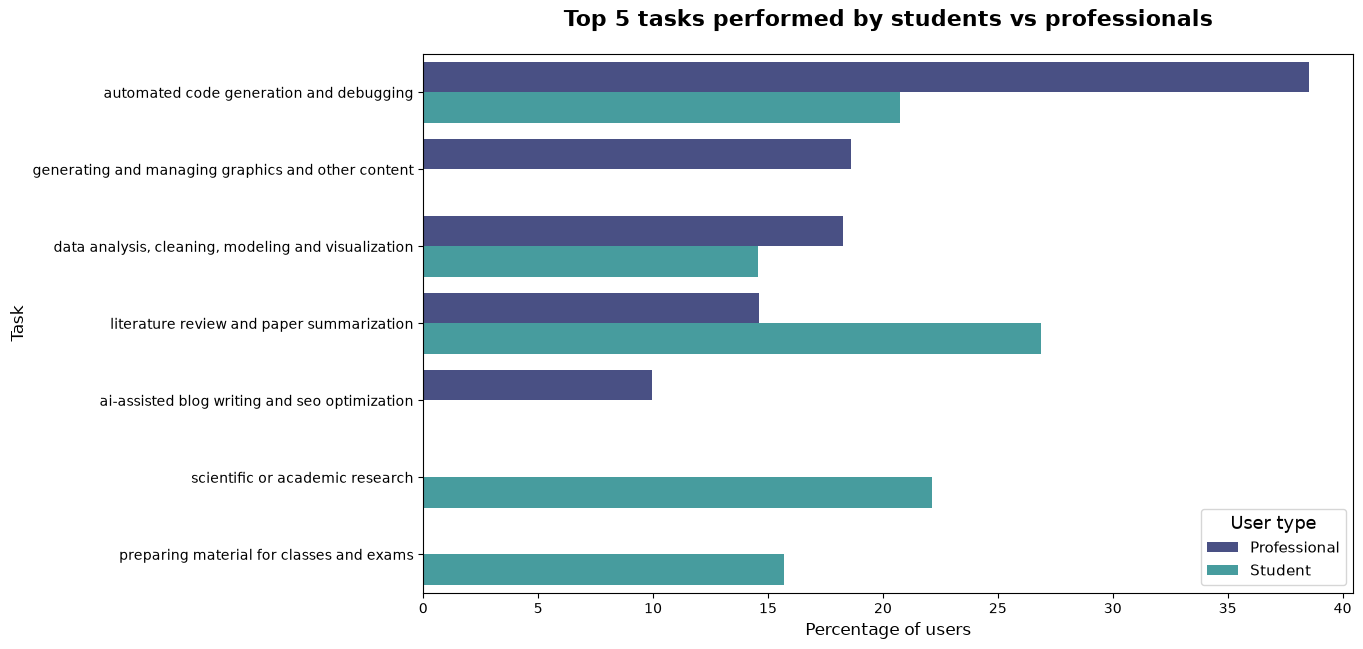

In [54]:
plt.figure(figsize=(12, 7))
sns.barplot(
    data = top_tasks.assign(Percentage = top_tasks.groupby('User_Type')['Number_Of_Users'].transform(lambda x: (x / x.sum()) * 100)), 
    x = 'Percentage', 
    y = 'Standardized_Task', 
    hue ='User_Type',
    palette = 'mako'
)
plt.title('Top 5 tasks performed by students vs professionals', fontsize = 16, fontweight = 'bold', pad = 20)
plt.xlabel('Percentage of users', fontsize = 12)
plt.ylabel('Task', fontsize = 12)
plt.legend(title = 'User type', title_fontsize = '13', fontsize = '11')
plt.show()

Students tend to use AI more often for paper reviews, summaries, and other types of academic research. This makes more than 40% of students' most performed tasks.    
On the other hand, professionals focus more on generating code and debugging, which is done by almost 40% of them.

#### Visual representation of how activities (tasks) performed impact productivity rates

In [55]:
df_exploded = df_exploded.reset_index(drop = True)
taskOrder = (
    df_exploded.groupby('Standardized_Task')['Productivity_Score']
    .mean()
    .sort_values(ascending=False).head(20)
    .index
)

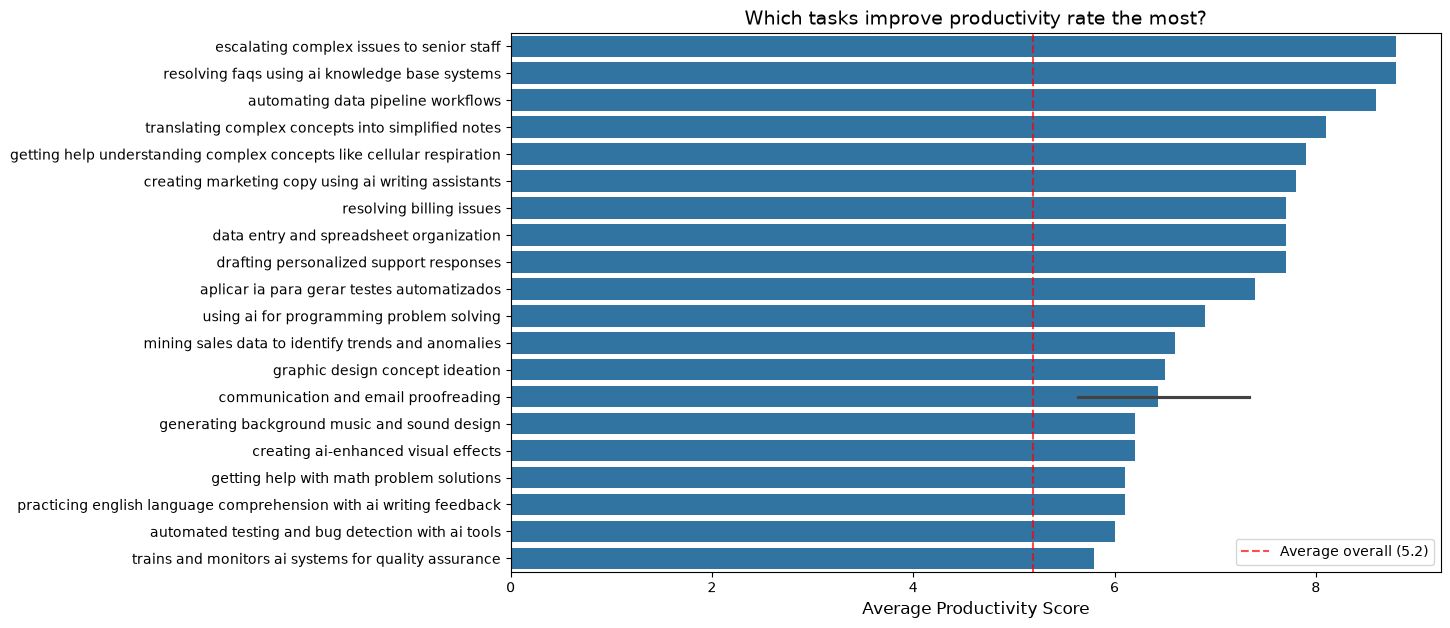

In [56]:
plt.figure(figsize = (12, 7))
sns.barplot(
    data = df_exploded,
    x = 'Productivity_Score',
    y = 'Standardized_Task',
    order = taskOrder
)
plt.title('Which tasks improve productivity rate the most?', fontsize = '14')
plt.xlabel('Average Productivity Score', fontsize=12)
plt.ylabel('', fontsize=12)
overall_mean = df_exploded['Productivity_Score'].mean()
plt.axvline(overall_mean, color='red', linestyle='--', alpha=0.7, label=f'Average overall ({overall_mean:.1f})')
plt.legend()

Noticed that most of these tasks were the least performed (less than 3 times mentioned), I need to "remove the noise" by filtering data.

In [57]:
task_counts = df_exploded['Standardized_Task'].value_counts()
frequent_tasks = task_counts[task_counts >= 10].index
df_filtered = df_exploded[df_exploded['Standardized_Task'].isin(frequent_tasks)]

In [58]:
taskOrder = (
    df_filtered.groupby('Standardized_Task')['Productivity_Score']
    .mean()
    .sort_values(ascending=False).head(20)
    .index
)

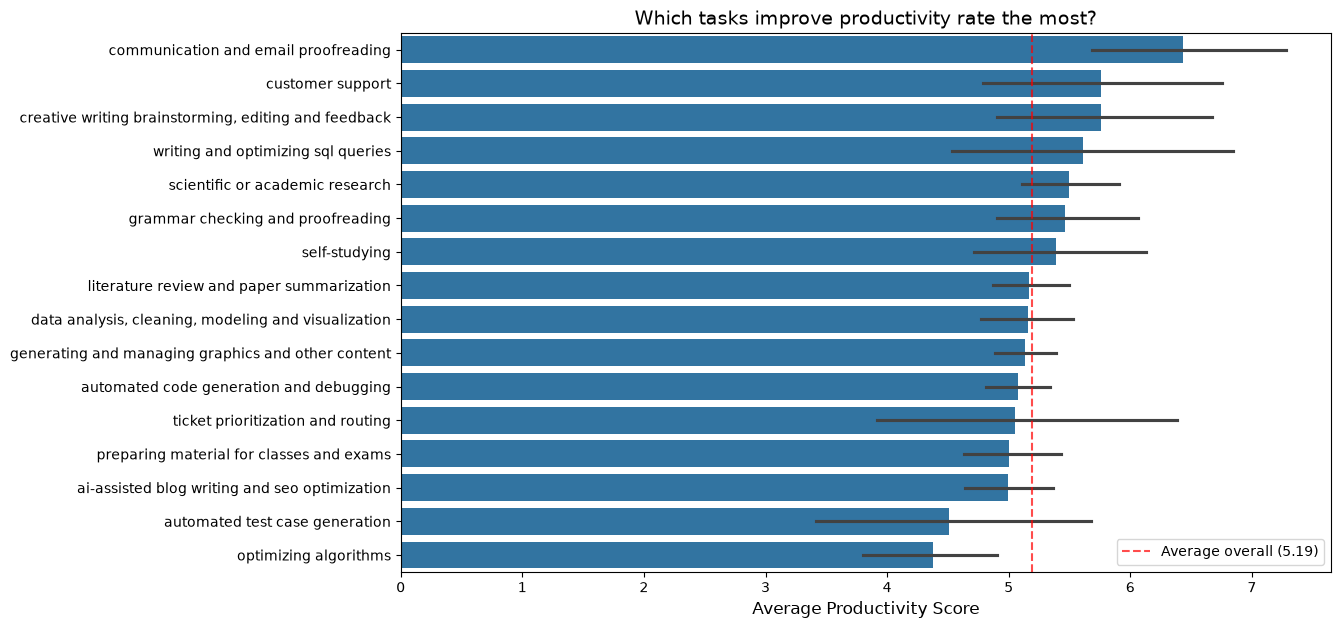

In [59]:
plt.figure(figsize = (12, 7))
sns.barplot(
    data = df_filtered,
    x = 'Productivity_Score',
    y = 'Standardized_Task',
    order = taskOrder
)
plt.title('Which tasks improve productivity rate the most?', fontsize = '14')
plt.xlabel('Average Productivity Score', fontsize=12)
plt.ylabel('', fontsize=12)
overall_mean = df_filtered['Productivity_Score'].mean()
plt.axvline(overall_mean, color='red', linestyle='--', alpha=0.7, label=f'Average overall ({overall_mean:.2f})')
plt.legend()

Turns out that the most performed tasks (code generation and debugging) do not actually affect productivity as much as some other activities, such as communication and email proofreading or customer support. In fact, the most performed task (code generaton and debugging) is below average productivity score (5,2), meaning that, even though it seems helpful, it might not help people work as fast as they feel.

### Analysis of correlation amongst numeric data  

Does the amount of money spent monthly on AI affect productivity or satisfaction scores?  
Does using AI for more hours daily increase productivity or satisfaction?  
Are any other two columns correlated?

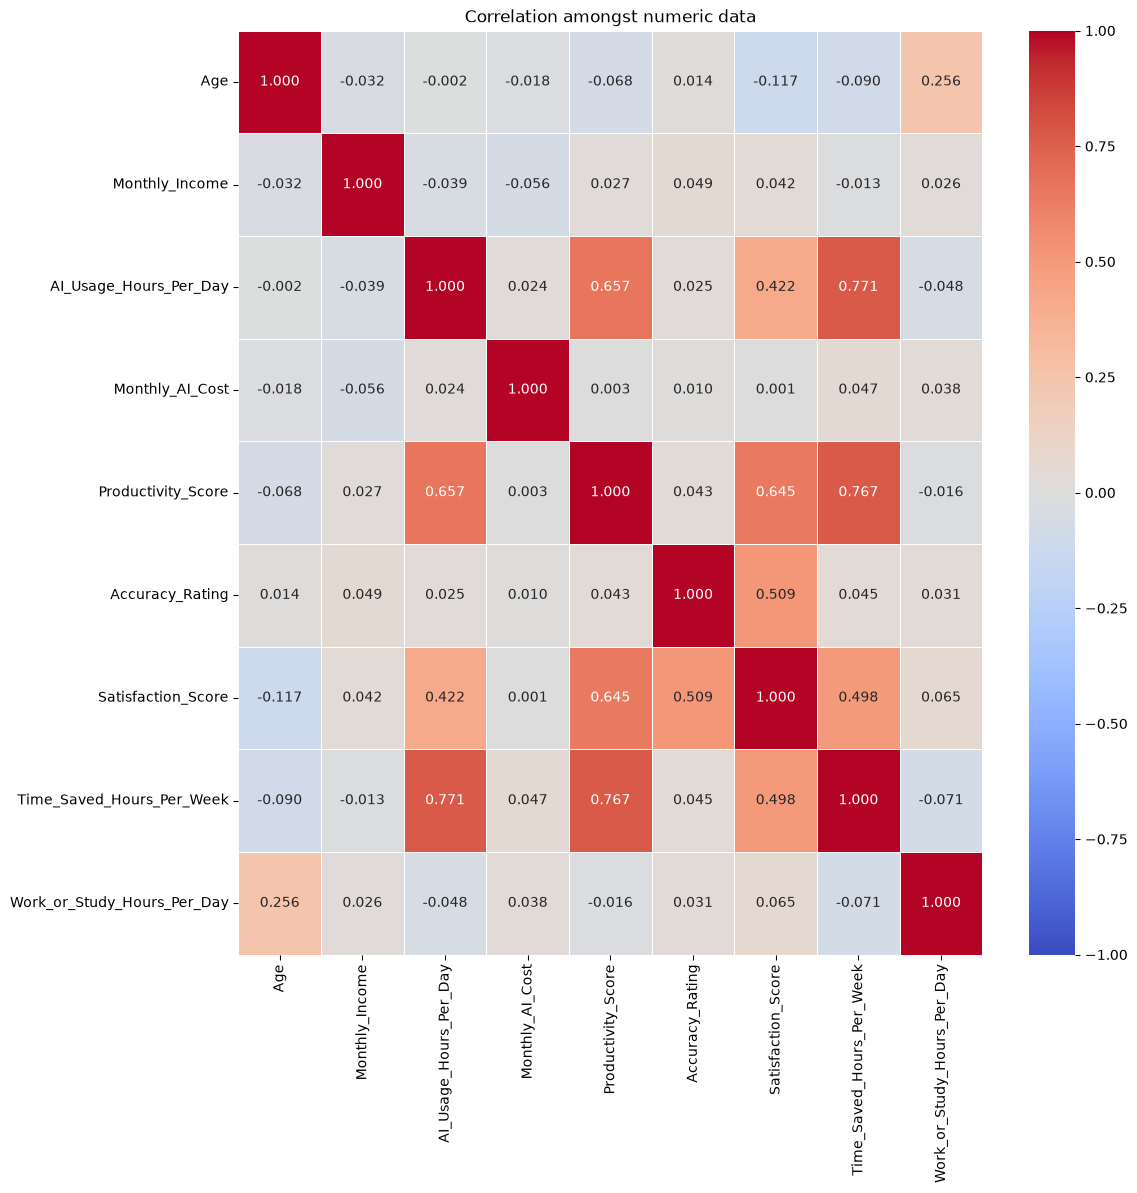

In [60]:
num_df = df_filtered.select_dtypes(include = ['float64', 'int64'])
correlation = num_df.corr()
plt.figure(figsize = (12, 12))

sns.heatmap(correlation, annot = True, cmap = 'coolwarm', fmt = '.3f', vmin = -1, vmax = 1, linewidths = 0.5) 
# using .3f because less decimal spaces did not give specific enough results
plt.title('Correlation amongst numeric data')
plt.show()

As it is visible in the graph, the correlation coefficient between AI usage hours per day and productivity score is 0.657, meaning that, in most cases, the more hours one uses AI for, the better the productivity.  
AI usage hours seem to slightly improve satisfaction score, as the correlation coefficient is only 0.422.  
As one would premise, productivity scores are affected by satisfaction score, since their correlation coefficient is 0.645. Productivity score is also strongly connected with time saved per week, as their coefficient is 0.767, almost highest of all shown. 
The strongest positive correlation coefficient, 0.771, is the one between AI usage hours per day and time saved hours per week, meaning that the greatest the amount of time spent using AI, the more hours of work saved weekly.
It seems that monthly AI cost barely affects any other measurement, since its correlation coefficients with other attributes are around 0.   
Monthly income and age are also not correlated with anything else.

### Analysis of correlation between AI tools and satisfaction/productivity scores

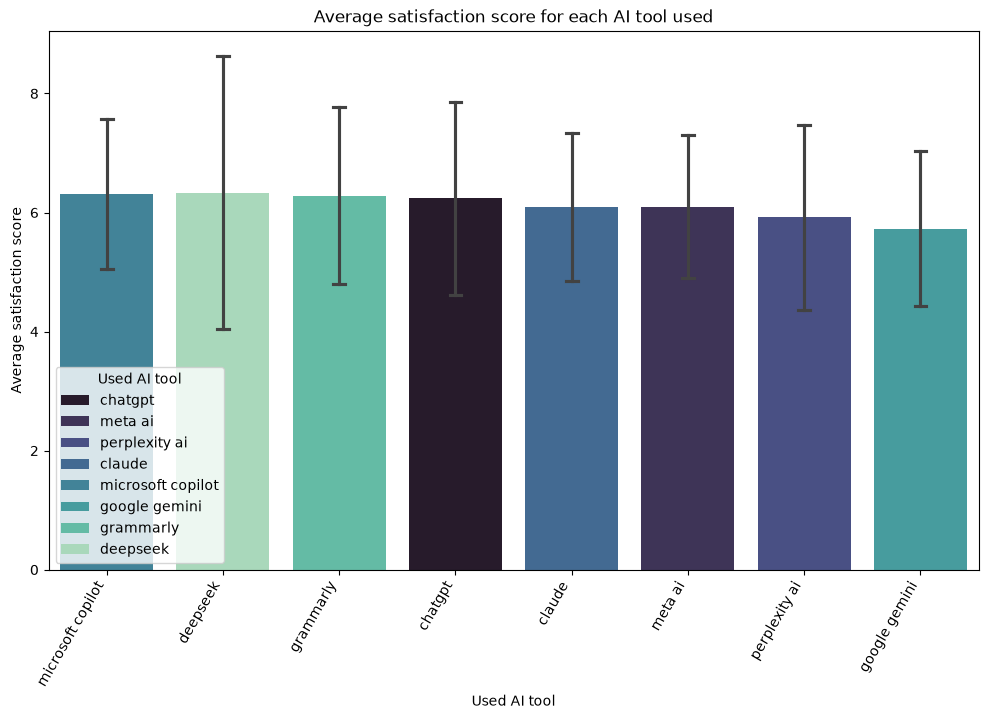

In [61]:
plt.figure(figsize = (12, 7))
order_mean = df_exploded.groupby('AI_Tool')['Satisfaction_Score'].mean().sort_values(ascending = False).index
sns.barplot(data = df, x = 'AI_Tool', y = 'Satisfaction_Score', order = order_mean, palette = 'mako', hue = 'AI_Tool', errorbar = 'sd', capsize = 0.1)
plt.title('Average satisfaction score for each AI tool used')
plt.xlabel('Used AI tool')
plt.ylabel('Average satisfaction score')
plt.legend(title = 'Used AI tool')
plt.xticks(rotation = 60, ha = 'right')
plt.show()

There is barely any difference between chosen AI tools and satisfaction scores, but DeepSeek has the greatest standard deviation among its users' satisfaction values.

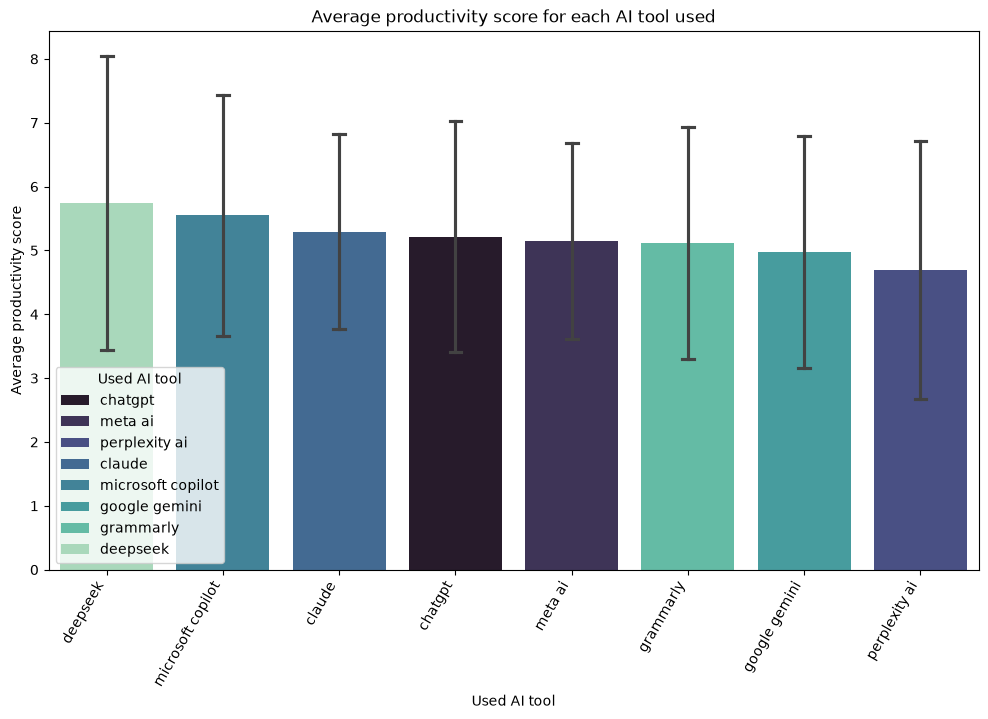

In [62]:
plt.figure(figsize = (12, 7))
orderMeanProductivity = df.groupby('AI_Tool')['Productivity_Score'].mean().sort_values(ascending = False).index
sns.barplot(data = df, order = orderMeanProductivity, x = 'AI_Tool', y = 'Productivity_Score', palette = 'mako', hue = 'AI_Tool', errorbar = 'sd', capsize = 0.1)
plt.title('Average productivity score for each AI tool used')
plt.xlabel('Used AI tool')
plt.ylabel('Average productivity score')
plt.legend(title = 'Used AI tool')
plt.xticks(rotation = 60, ha = 'right')
plt.show()

DeepSeek has the highest average productivity score (almost 6 on a scale 0-8), whereas Perplexity has the smallest (about 5). Standard deviations do not vary here as much as they did in the previous graph.

## Conclusion

Based on the data analysis, we can draw several key insights regarding user tasks and productivity:  
* Student vs. Professional Tasks: The analysis reveals a distinct difference in the types of tasks performed. Students primarily focused on literature review, academic research etc., accounting for more than 40% of their activities. In contrast, professionals spent the majority of their time on automated code generation and debugging.
* Productivity trends: The overall average productivity score across all users was 5.2. The task which proved to be the most impactful on productivity was communication and email proofreading, followed by customer support and help in creative writing / brainstorming ideas.
* Most frequent task: Across the entire dataset, automated code generation and debugging was the most common activity, suggesting that, ironically, people use advanced technology to create other types of technology.
* Limitations: It is important to note that this dataset is limited by its size and self-reported productivity metrics, but it provides a solid foundational understanding of how daily tasks impact overall output.